# Getting Started with ContextNet

**ContextNet** extends [NicheNet](https://github.com/saeyslab/nichenetr) by replacing its generic gene regulatory network with a **context-specific GRN** constructed from your own single-cell multiomics data. This produces ligand-target predictions that reflect the regulatory landscape of your specific biological system.

## Learning Objectives

By the end of this tutorial, you will be able to:

- Import a context-specific GRN from a gene × TF matrix
- Integrate it with NicheNet's prior knowledge networks
- Run ligand activity prediction using cell type comparison mode
- Interpret ligand activity scores and ligand-target heatmaps
- Navigate ContextNet's S4 object system (ContextGRN, ContextNetwork, ContextResult)

## Framework Overview

The framework comprises three components:

1. **GRN inference workflow** — constructs context-specific TF-target relationships from matched scRNA-seq + scATAC-seq data
2. **ContextNet** (this package) — integrates the GRN with NicheNet and performs ligand activity prediction
3. **[ccflowR](https://github.com/settylab/ccflowR)** — visualizes signaling flow using Sankey diagrams

> **When to use this tutorial:**
> - You are new to ContextNet and want a quick end-to-end example
> - You want to understand the core objects and workflow
>
> **Use another tutorial instead if:**
> - You want the full workflow with visualization and export → [02-standard-workflow](02-standard-workflow.ipynb)
> - You have biological replicates and multiple conditions → [03-multicondition-workflow](03-multicondition-workflow.ipynb)

## What is a Context-Specific GRN?

A **gene regulatory network (GRN)** describes how transcription factors (TFs) regulate target genes. NicheNet uses a generic GRN compiled from public databases (TRRUST, RegNetwork, etc.). While comprehensive, these networks may not capture the regulatory relationships active in your specific experimental context.

A **context-specific GRN** is inferred directly from your single-cell multiomics data (scRNA-seq + scATAC-seq), capturing TF-target relationships that are actually active in your cells.

| Aspect | Generic GRN (NicheNet default) | Context-Specific GRN (ContextNet) |
|--------|-------------------------------|-----------------------------------|
| Source | Public databases | Your multiomics data |
| Coverage | Broad (all known interactions) | Focused (active in your context) |
| Specificity | May include irrelevant edges | Reflects your cell types/conditions |
| Result | Generic predictions | Context-relevant predictions |

## Setup

In [1]:
suppressPackageStartupMessages({
    library(ContextNet)
    library(Seurat)
    library(nichenetr)
    library(ggplot2)
    library(showtext)
})

# Use showtext for clean font rendering (avoids text overlap in plots)
showtext_auto()
font_add_google("Roboto", "roboto")
theme_set(theme_minimal(base_family = "roboto"))

Warning message:
“replacing previous import ‘e1071::element’ by ‘ggplot2::element’ when loading ‘nichenetr’”
Warning message in checkDepPackageVersion(dep_pkg = "TMB"):
“Package version inconsistency detected.
glmmTMB was built with TMB version 1.9.16
Current TMB version is 1.9.17
Please re-install glmmTMB from source or restore original ‘TMB’ package (see '?reinstalling' for more information)”


In [2]:
check_ecosystem(verbose = TRUE)

✔ ContextNet 0.1.0

✔ nichenetr 2.2.1.1

✔ multinichenetr installed

✔ Seurat 5.3.0

✔ reticulate installed (Python integration available)

ℹ contextnet-pipeline not found (optional, for GRN construction)

ℹ ccflowR not found (optional, for sankey flow visualization)

ℹ Install: `devtools::install_github('username/ccflowR')`



In [3]:
# ╔══════════════════════════════════════════════════════════════╗
# ║                    USER CONFIGURATION                       ║
# ║  Edit these paths/values to match your data.                ║
# ║  This is the ONLY cell you need to modify.                  ║
# ╚══════════════════════════════════════════════════════════════╝

DATA_PATH       <- "/Volumes/yhuang2/ContextNet/data"
GRN_FILE        <- file.path(DATA_PATH, "gene_x_tf.csv")
SEURAT_FILE     <- file.path(DATA_PATH, "seurat_obj.rds")

# NicheNet prior knowledge networks
# Option 1: Local directory containing .rds files (if you already have them)
NICHENET_DB     <- DATA_PATH
# Option 2: Auto-download from Zenodo and cache locally (first run downloads ~1 GB)
# NICHENET_DB   <- "~/.nichenet_data"
# Option 3: Use nichenetr package built-in data (if installed from GitHub)
# NICHENET_DB   <- NULL

# Analysis parameters — cell type comparison for basal identity
SENDER          <- NULL           # Auto-detect: all cell types with >500 cells
RECEIVER        <- "basal"
GROUP_COL       <- "Fine_Cell_Types"
IDENT_COL       <- "Fine_Cell_Types"
IDENT_1         <- "basal"
IDENT_2         <- c("parabasal", "suprabasal")
SUBSET_CATEGORY <- "C"            # Subset Seurat to contralateral tissue
MIN_CELLS       <- 500            # Minimum cells for sender cell types

### NicheNet Prior Knowledge Networks

ContextNet requires NicheNet's prior knowledge networks (ligand-receptor interactions and weighted signaling/regulatory networks). There are three ways to obtain them:

| Option | `NICHENET_DB` | Notes |
|--------|---------------|-------|
| **Local files** | Path to directory with `.rds` files | Fastest; use if you already downloaded them |
| **Auto-download** | `"~/.nichenet_data"` (any cache dir) | Downloads from [Zenodo](https://zenodo.org/record/7074291) on first run (~1 GB), then reuses cache |
| **nichenetr package** | `NULL` | Uses built-in data from [nichenetr](https://github.com/saeyslab/nichenetr) (must be installed from GitHub) |

The required files (from [NicheNet v2 on Zenodo](https://zenodo.org/record/7074291)):
- `lr_network_human_21122021.rds` — ligand-receptor interactions
- `weighted_networks_nsga2r_final.rds` — weighted signaling and regulatory networks

For MultiNicheNet (Tutorial 03), an extended LR network is also used from [Zenodo record 10229222](https://zenodo.org/record/10229222):
- `lr_network_human_allInfo_30112033.rds`

You can also download manually with `load_nichenet_data()`:
```r
nichenet_data <- load_nichenet_data(cache_dir = "~/.nichenet_data")
```

## Quick Example: 4-Step Workflow

```
GRN (csv) → import_grn() → integrate_networks() → predict_ligand_activity_nichenet() → Visualize
```

We use an HNSCC dataset (contralateral epithelium) and ask: **which ligands drive basal-cell-specific gene expression** compared to parabasal and suprabasal cells? This uses **cell type comparison mode** (`de_subset_receiver = FALSE`), computing DE across all cells rather than within receiver cells only.

### Step 1: Import Your GRN

The GRN is a gene × TF matrix (CSV) where rows are target genes, columns are TFs, and values are regulatory weights inferred from matched scRNA-seq + scATAC-seq data.

In [4]:
grn <- import_grn(GRN_FILE)
grn

→ Loading GRN from: /fh/fast/setty_m/user/yhuang2/ContextNet/data/gene_x_tf.csv

ℹ Matrix dimensions: 17226 genes x 701 TFs

→ Normalizing weights per TF...

→ Converting to edge list...

✔ Imported GRN:

TFs: 701

Targets: 11607

Edges: "2,334,753"



── ContextGRN ──────────────────────────────────────────────────────────────────



Edges: "2,334,753"

TFs: 701

Targets: 11607



ℹ Source: contextnet-pipeline

ℹ Created: 2026-03-23 21:50:43



ℹ Top TFs (by target count): "SP1", "ZNF543", "ZSCAN22", "ZNF770", and "ZNF263"



### Step 2: Integrate with NicheNet

Replace NicheNet's generic GRN with your context-specific one. NicheNet's curated ligand-receptor interactions and signaling pathways are preserved. The result is a context-specific ligand-target matrix computed via Personalized PageRank.

> **Using the matrix with nichenetr/multinichenetr directly:** After this step, you can extract the ligand-target matrix with `ligand_target_matrix(network)` and use it directly in your own [nichenetr](https://github.com/saeyslab/nichenetr/blob/master/vignettes/seurat_steps.md) or [multinichenetr](https://github.com/saeyslab/multinichenetr/blob/main/vignettes/basic_analysis_steps_MISC.md) workflows. ContextNet's convenience functions (Steps 3-4 below) wrap these packages, but you are not locked in — the matrix is a standard R matrix that drops into any nichenetr function expecting a `ligand_target_matrix` argument.

In [5]:
# ~10 minutes — constructs ligand-target matrix via Personalized PageRank
network <- integrate_networks(
    grn,
    nichenet_database = NICHENET_DB,
    mode = "replace"                   # Replace NicheNet's generic GRN entirely
)
network



── Network Integration ──



→ Loading NicheNet networks...

ℹ Loading from: /fh/fast/setty_m/user/yhuang2/ContextNet/data

✔ Loaded lr_network from lr_network_human_21122021.rds

✔ Loaded weighted_networks from weighted_networks_nsga2r_final.rds

ℹ Ligands from lr_network: 1226

ℹ GRN edges: "2,334,753"

ℹ GRN TFs: 701

ℹ GRN targets: 11607

→ Integrating networks (mode: "replace")...

ℹ PPR damping_factor: 0.7886

ℹ LTF cutoff: 0.9256

→ Constructing ligand-target matrix (this may take a while)...

✔ Constructed ligand-target matrix:

Ligands: 1226

Targets: 25337

Non-zero entries: "14,217,826"



── ContextNetwork ──────────────────────────────────────────────────────────────



Ligands: "1,226"

Targets: "25,337"

Integration mode: "replace"

Signaling edges: "3,923,501"



ℹ Source GRN: 2334753 edges



ℹ Created: 2026-03-23 22:00:54



### Step 3: Run Communication Analysis

We use **cell type comparison mode** (`de_subset_receiver = FALSE`) to find basal-specific genes compared to parabasal and suprabasal cells. All cell types with sufficient cells serve as potential senders.

In [6]:
seurat_obj <- readRDS(SEURAT_FILE)
seurat_c <- subset(seurat_obj, subset = category == SUBSET_CATEGORY)

# Auto-detect senders: all cell types with sufficient cells
celltype_counts <- table(seurat_c[[GROUP_COL]][, 1])
if (is.null(SENDER)) {
    SENDER <- names(celltype_counts)[celltype_counts > MIN_CELLS]
}

cat("Senders:", paste(SENDER, collapse = ", "), "\n")
cat("Receiver:", RECEIVER, "\n")
cat("Comparison:", paste(IDENT_1, collapse = "+"), "vs", paste(IDENT_2, collapse = "+"), "\n")

Senders: Endothelial, Fibroblast, Myeloid, Myofibroblast, T Cell, basal, dividing, parabasal, suprabasal 
Receiver: basal 
Comparison: basal vs parabasal+suprabasal 


In [7]:
# ~2 minutes — runs NicheNet ligand activity prediction
result <- predict_ligand_activity_nichenet(
    object = seurat_c,
    network = network,
    sender = SENDER,
    receiver = RECEIVER,
    group_col = GROUP_COL,
    ident_col = IDENT_COL,
    ident_1 = IDENT_1,
    ident_2 = IDENT_2,
    de_subset_receiver = FALSE,        # Cell type comparison: DE across all cells
    nichenet_database = NICHENET_DB
)

top_ligands(result)



── NicheNet Ligand Activity Prediction ─────────────────────────────────────────

ℹ Sender: "Endothelial, Fibroblast, Myeloid, Myofibroblast, T Cell, basal, dividing, parabasal, suprabasal"

ℹ Receiver: "basal"

ℹ DE comparison: "basal" vs "parabasal, suprabasal"

ℹ DE mode: across all cells

→ Computing DE genes: all cells, (basal) vs (parabasal, suprabasal)

Warning message:
“The `slot` argument of `GetAssayData()` is deprecated as of SeuratObject 5.0.0.
ℹ Please use the `layer` argument instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>.”
Warning message:
“`PackageCheck()` was deprecated in SeuratObject 5.0.0.
ℹ Please use `rlang::check_installed()` instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>.”
✔ Found 3471 DE genes

✔ Loaded lr_network from lr_network_human_21122021.rds



── NicheNet

[1] "JAM2"    "POSTN"   "SLURP2"  "KIRREL1" "CALM3"   "CALM2"   "CALM1"  
 [8] "COL18A1" "EFNA1"   "EZR"     "VEGFB"   "ANGPTL4" "NRG1"    "BMP7"   
[15] "ENTPD1"  "NECTIN3" "WNT4"    "CD47"    "CCN2"    "SFRP1"   "SLURP1" 
[22] "ADAM9"   "TSPAN3"  "LRRC4"   "MDK"     "JAML"    "VWF"     "DSC3"   
[29] "IL18"    "NLGN1"

### Step 4: Visualize Results

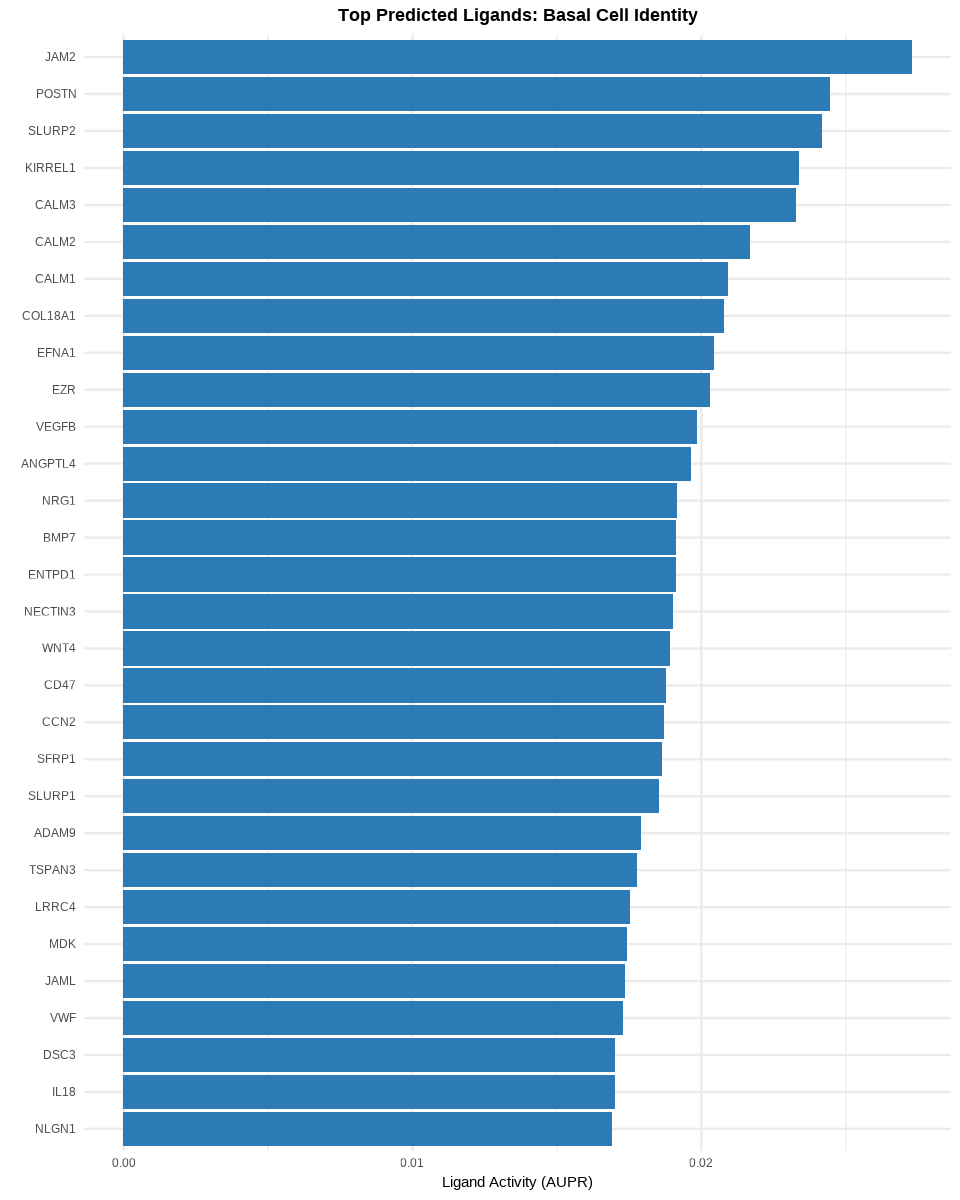

In [8]:
options(repr.plot.width = 8, repr.plot.height = 10)

activities <- ligand_activities(result)
best_ligands <- top_ligands(result)

top_act <- activities[activities$test_ligand %in% best_ligands, ]
top_act$test_ligand <- factor(top_act$test_ligand, levels = rev(best_ligands))

ggplot(top_act, aes(x = aupr_corrected, y = test_ligand)) +
    geom_col(fill = "#2C7BB6") +
    labs(x = "Ligand Activity (AUPR)", y = NULL,
         title = "Top Predicted Ligands: Basal Cell Identity") +
    theme_minimal() +
    theme(plot.title = element_text(hjust = 0.5, face = "bold"))

**Interpretation**: Each bar shows the AUPR (area under precision-recall curve) — how well a ligand's known targets overlap with the basal-specific DE genes. Higher AUPR means the ligand is more likely driving the observed basal gene expression program. JAM2 and POSTN top the ranking, consistent with their roles in epithelial adhesion and basement membrane signaling.

**Interpretation**: The heatmap shows the regulatory potential between top ligands (columns) and their predicted target genes (rows). Darker entries indicate stronger predicted regulatory connections from the context-specific ligand-target matrix. Ligands regulating many targets (dense columns) are predicted to have broad regulatory influence on the basal gene program.

In [9]:
options(repr.plot.width = 12, repr.plot.height = 10)

best_targets <- top_targets(result, n = 50)
ltm <- ligand_target_matrix(network)

target_rows <- intersect(best_targets, rownames(ltm))
ligand_cols <- intersect(best_ligands, colnames(ltm))
vis_matrix <- ltm[target_rows, ligand_cols, drop = FALSE]

nonzero <- vis_matrix[vis_matrix > 0]
if (length(nonzero) > 0) {
    vis_matrix[vis_matrix < quantile(nonzero, 0.33)] <- 0
}
vis_matrix <- vis_matrix[rowSums(vis_matrix) > 0, , drop = FALSE]

nichenetr::make_heatmap_ggplot(
    vis_matrix,
    y_name = "Target Gene",
    x_name = "Predicted Ligand",
    legend_title = "Regulatory\nPotential",
    color = "purple"
)

Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the nichenetr package.
  Please report the issue at <https://github.com/saeyslab/nichenetr/issues>.”
Warning message:
“The `size` argument of `element_line()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.
ℹ The deprecated feature was likely used in the nichenetr package.
  Please report the issue at <https://github.com/saeyslab/nichenetr/issues>.”


## Exploring ContextNet Objects

ContextNet uses S4 classes with accessor methods:

### ContextGRN

| Accessor | Returns |
|----------|--------|
| `edges(grn)` | Edge list (from, to, weight) |
| `tfs(grn)` | Character vector of TF names |
| `targets(grn)` | Character vector of target gene names |
| `regulons(grn)` | Named list: TF -> target gene vector |
| `length(grn)` | Number of edges |

### ContextNetwork

| Accessor | Returns |
|----------|--------|
| `ligand_target_matrix(network)` | Ligand-target regulatory potential matrix |
| `ligands(network)` | Character vector of ligand names |
| `targets(network)` | Character vector of target gene names |
| `integration_params(network)` | Integration parameters (mode, damping_factor, etc.) |

### ContextResult

| Accessor | Returns |
|----------|--------|
| `ligand_activities(result)` | Data frame of ligand activity scores |
| `top_ligands(result)` | Top-ranked ligand names |
| `top_targets(result)` | Top predicted target genes |
| `ligand_target_links(result)` | Ligand-target regulatory links |
| `parameters(result)` | Analysis parameters used |
| `as.data.frame(result)` | Ligand activities as data frame |

All objects track **provenance** (creation time, package version, source function) automatically.

In [ ]:
sessionInfo()

## Key Parameters

| Parameter | Required | Description |
|-----------|----------|-------------|
| `sender` | Yes | Sender cell type(s) expressing ligands |
| `receiver` | Yes | Receiver cell type expressing receptors and targets |
| `ident_col` | Yes* | Metadata column for DE grouping |
| `ident_1` | Yes* | Value(s) for DE group 1 (upregulated genes) — can be a vector |
| `ident_2` | Yes* | Value(s) for DE group 2 (reference) — can be a vector |
| `de_subset_receiver` | No | Whether to subset to receiver cells first (default: TRUE) |
| `geneset_oi` | No | Custom gene set; auto-computed from DE if NULL |
| `group_col` | No | Metadata column with cell type labels (default: "cell_type") |

*Required unless `geneset_oi` is provided directly

### Two DE Comparison Modes

**Mode 1: Condition comparison** (`de_subset_receiver = TRUE`, default)

Compare conditions *within* the receiver cell type. Use when you have experimental conditions (disease/control, treated/untreated).

```r
# Compare Disease vs Control WITHIN Fibroblast cells
result <- predict_ligand_activity_nichenet(
    object = seurat_obj, network = network,
    sender = "Macrophage", receiver = "Fibroblast",
    ident_col = "disease_status",
    ident_1 = "Disease", ident_2 = "Control"
)
```

**Mode 2: Cell type comparison** (`de_subset_receiver = FALSE`)

Compare cell types directly *across* all cells. Use when finding cell type-specific marker genes.

```r
# Find basal-specific genes vs parabasal/suprabasal
result <- predict_ligand_activity_nichenet(
    object = seurat_obj, network = network,
    sender = all_celltypes, receiver = "basal",
    ident_col = "cell_type",
    ident_1 = "basal", ident_2 = c("parabasal", "suprabasal"),
    de_subset_receiver = FALSE
)
```

## Next Steps

- **[02-standard-workflow](02-standard-workflow.ipynb)**: Full NicheNet workflow with condition comparison, Sankey visualization, and export
- **[03-multicondition-workflow](03-multicondition-workflow.ipynb)**: Multi-condition differential analysis with biological replicates (MultiNicheNet)

### Using nichenetr / multinichenetr directly

ContextNet's main contribution is the **context-specific ligand-target matrix**. If you prefer to run your own analysis code rather than using ContextNet's wrapper functions, extract the matrix after Step 2 and follow the upstream tutorials:

```r
# Extract the context-specific ligand-target matrix
ltm <- ligand_target_matrix(network)

# Use directly in nichenetr or multinichenetr workflows
# — replace the default ligand_target_matrix with ltm
```

- **nichenetr tutorials**: [Step-by-step analysis](https://github.com/saeyslab/nichenetr/blob/master/vignettes/seurat_steps.md) | [Seurat wrapper](https://github.com/saeyslab/nichenetr/blob/master/vignettes/seurat_wrapper.md) | [Circos visualization](https://github.com/saeyslab/nichenetr/blob/master/vignettes/seurat_wrapper_circos.md)
- **multinichenetr tutorials**: [Basic analysis](https://github.com/saeyslab/multinichenetr/blob/main/vignettes/basic_analysis_steps_MISC.md) | [Pairwise comparison](https://github.com/saeyslab/multinichenetr/blob/main/vignettes/pairwise_analysis_MISC.md) | [Paired design](https://github.com/saeyslab/multinichenetr/blob/main/vignettes/paired_analysis_SCC.knit.md)